# 05d · Red neuronal en Keras (Módulo 4)

> **Flujo del proyecto** (diagrama del profesor)
> `01 Limpieza` → `02 Exploración` → `03 Creación de variables` → `04 Preparación (split temporal + folds)` →
> `05a Logística` · `05b Random Forest` · `05c XGBoost` · `05d Red neuronal` (cada uno: selección de variables → hiperparámetros) →
> `06 Selección del mejor modelo y prueba final en test`


    **Qué red y por qué:** un perceptrón multicapa (MLP). Los datos son una **tabla** (una fila por pedido); las redes
    convolucionales son para imágenes y las recurrentes para secuencias.

    **Misma rama del diagrama que los demás modelos, adaptada a una red:**
    1. **Selección de variables:** RFECV necesita coeficientes o importancias, que una red no tiene. Comparamos con el K-Fold temporal
       **conjuntos candidatos**: todas las variables, el RFECV de cada modelo clásico, su unión y su intersección.
    2. **Hiperparámetros:** búsqueda aleatoria sobre arquitectura, dropout, regularización L2, tasa de aprendizaje y batch.
    3. **Evaluación** con los mismos 5 folds, train vs. validación, y umbral fuera de fold.

    **Control del sobreajuste:** EarlyStopping + Dropout + L2. El early stopping usa la **cola más reciente (15 %) del train
    de cada fold**, nunca el fold de validación ni el test (si usara la validación, su score quedaría inflado).
    Desbalance: pesos por clase balanceados. **El test no se usa en este notebook.**

In [1]:
import sys, json, time, warnings
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import config, viz
viz.aplicar_estilo()
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

from src import modelos as M, evaluacion as E, red_neuronal as R
NOMBRE = config.NOMBRE_RED
COLOR = viz.COLOR_MODELO[NOMBRE]

In [2]:
X_train = pd.read_parquet(config.DATOS_PROCESSED / "X_train.parquet")
meta_train = pd.read_parquet(config.DATOS_PROCESSED / "meta_train.parquet")
y_train = meta_train["delivery_late"]
folds = [(np.array(f["train"]), np.array(f["val"])) for f in json.loads((config.DATOS_PROCESSED / "folds.json").read_text())]
print(f"Train: {X_train.shape} | {len(folds)} folds temporales | tasa de tardíos {y_train.mean():.2%}")

Train: (68287, 105) | 5 folds temporales | tasa de tardíos 7.59%


## Paso 1 · Selección de variables por conjuntos candidatos

In [3]:
candidatos = {"Todas": list(X_train.columns)}
for n in config.MODELOS_CLASICOS:
    candidatos[f"RFECV {n}"] = json.loads((config.MODELOS / config.CLAVES_MODELO[n] / "best_features.json").read_text())
rfecv_sets = [set(candidatos[f"RFECV {n}"]) for n in config.MODELOS_CLASICOS]
candidatos["Unión RFECV"] = [c for c in X_train.columns if c in set.union(*rfecv_sets)]
interseccion = [c for c in X_train.columns if c in set.intersection(*rfecv_sets)]
if len(interseccion) >= 5:
    candidatos["Intersección RFECV"] = interseccion

resultados_sets, corridas = [], {}
for nombre_set, cols in candidatos.items():
    t0 = time.time()
    tabla, oof, umbral = E.evaluar_cv(R.ajustar_predecir_red(cols, R.CONFIG_BASE), X_train, y_train, folds)
    corridas[("set", nombre_set)] = (tabla, oof, umbral)
    resultados_sets.append({"Conjunto": nombre_set, "Variables": len(cols),
                            "PR-AUC val prom": tabla["PR-AUC val"].mean(), "PR-AUC val desv": tabla["PR-AUC val"].std(),
                            "PR-AUC train prom": tabla["PR-AUC train"].mean(), "segundos": round(time.time() - t0)})
    print(f"{nombre_set:28s} {len(cols):3d} vars | PR-AUC val {tabla['PR-AUC val'].mean():.4f}")
resultados_sets = pd.DataFrame(resultados_sets).sort_values("PR-AUC val prom", ascending=False).reset_index(drop=True)
display(resultados_sets.round(4))

# Mejor conjunto; empates (< tolerancia) -> el de menos variables
mejor_pr = resultados_sets["PR-AUC val prom"].max()
empatados = resultados_sets[resultados_sets["PR-AUC val prom"] >= mejor_pr - config.TOLERANCIA_EMPATE]
mejor_set = empatados.sort_values("Variables").iloc[0]["Conjunto"]
columnas = candidatos[mejor_set]
print(f"Conjunto elegido: {mejor_set} ({len(columnas)} variables)")

Todas                        105 vars | PR-AUC val 0.1542


RFECV Regresión Logística     65 vars | PR-AUC val 0.1724


RFECV Random Forest          105 vars | PR-AUC val 0.1542


RFECV XGBoost                 35 vars | PR-AUC val 0.1818


Unión RFECV                  105 vars | PR-AUC val 0.1542


Intersección RFECV            32 vars | PR-AUC val 0.1561


,Conjunto,Variables,PR-AUC val prom,PR-AUC val desv,PR-AUC train prom,segundos
0,RFECV XGBoost,35,0.1818,0.1327,0.1292,16
1,RFECV Regresión Logística,65,0.1724,0.1271,0.1473,13
2,Intersección RFECV,32,0.1561,0.1160,0.1247,14
3,Todas,105,0.1542,0.1084,0.1461,13
4,RFECV Random Forest,105,0.1542,0.1084,0.1461,13
5,Unión RFECV,105,0.1542,0.1084,0.1461,14


Conjunto elegido: RFECV XGBoost (35 variables)


## Paso 2 · Búsqueda de hiperparámetros

In [4]:
rng = np.random.default_rng(config.RANDOM_STATE)
espacio = {"capas": [(16,), (32,), (32, 16), (64, 32), (64, 32, 16)], "dropout": [0.1, 0.2, 0.3, 0.4],
           "l2": [1e-4, 1e-3, 1e-2], "lr": [3e-4, 1e-3, 3e-3], "batch": [256, 512, 1024]}
configs = [dict(R.CONFIG_BASE)]   # la configuración base ya se evaluó en el paso 1
while len(configs) < 6:
    c = {k: v[rng.integers(len(v))] for k, v in espacio.items()}
    if c not in configs:
        configs.append(c)

filas = []
for i, cfg in enumerate(configs):
    t0 = time.time()
    if i == 0:
        tabla, oof, umbral = corridas[("set", mejor_set)]
    else:
        tabla, oof, umbral = E.evaluar_cv(R.ajustar_predecir_red(columnas, cfg), X_train, y_train, folds)
    corridas[("cfg", i)] = (tabla, oof, umbral)
    filas.append({"Config": i, **{k: str(v) for k, v in cfg.items()},
                  "PR-AUC val prom": tabla["PR-AUC val"].mean(), "PR-AUC val desv": tabla["PR-AUC val"].std(),
                  "PR-AUC train prom": tabla["PR-AUC train"].mean(), "segundos": round(time.time() - t0)})
    print(f"config {i}: {cfg} -> PR-AUC val {tabla['PR-AUC val'].mean():.4f}")
busqueda = pd.DataFrame(filas).sort_values("PR-AUC val prom", ascending=False).reset_index(drop=True)
display(busqueda.round(4))
i_mejor = int(busqueda.loc[0, "Config"])
mejor_cfg = configs[i_mejor]
print("Mejor configuración:", mejor_cfg)

config 0: {'capas': (32, 16), 'dropout': 0.3, 'l2': 0.001, 'lr': 0.0005, 'batch': 512} -> PR-AUC val 0.1818


config 1: {'capas': (16,), 'dropout': 0.4, 'l2': 0.001, 'lr': 0.001, 'batch': 512} -> PR-AUC val 0.1741


config 2: {'capas': (64, 32, 16), 'dropout': 0.1, 'l2': 0.01, 'lr': 0.0003, 'batch': 256} -> PR-AUC val 0.1895


config 3: {'capas': (32, 16), 'dropout': 0.4, 'l2': 0.01, 'lr': 0.003, 'batch': 1024} -> PR-AUC val 0.1697


config 4: {'capas': (64, 32), 'dropout': 0.3, 'l2': 0.0001, 'lr': 0.003, 'batch': 512} -> PR-AUC val 0.1825


config 5: {'capas': (32, 16), 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.003, 'batch': 1024} -> PR-AUC val 0.1649


,Config,capas,dropout,l2,lr,batch,PR-AUC val prom,PR-AUC val desv,PR-AUC train prom,segundos
0,2,"(64, 32, 16)",0.1,0.01,0.0003,256,0.1895,0.1317,0.1440,20
1,4,"(64, 32)",0.3,0.0001,0.003,512,0.1825,0.1308,0.1582,8
2,0,"(32, 16)",0.3,0.001,0.0005,512,0.1818,0.1327,0.1292,0
3,1,"(16,)",0.4,0.001,0.001,512,0.1741,0.1220,0.1398,14
4,3,"(32, 16)",0.4,0.01,0.003,1024,0.1697,0.1265,0.1248,8
5,5,"(32, 16)",0.2,0.0001,0.003,1024,0.1649,0.1230,0.1533,8


Mejor configuración: {'capas': (64, 32, 16), 'dropout': 0.1, 'l2': 0.01, 'lr': 0.0003, 'batch': 256}


## Paso 3 · Evaluación con el K-Fold temporal (mejor configuración)

,Fold,PR-AUC train,PR-AUC val,ROC-AUC train,ROC-AUC val,% tardíos train,% tardíos val,Precision val,Recall val,F1 val
0,1,0.1331,0.0320,0.8051,0.5321,3.8359,2.9347,0.0312,0.5210,0.0589
1,2,0.0970,0.0935,0.7358,0.6297,3.2304,5.3159,0.1467,0.1355,0.1409
2,3,0.1084,0.2533,0.7402,0.7373,3.5112,9.9552,0.2976,0.3548,0.3237
3,4,0.1846,0.2029,0.7551,0.6928,5.3299,10.7372,0.1482,0.7872,0.2494
4,5,0.1970,0.3658,0.7481,0.7854,5.3295,12.5648,0.3272,0.5329,0.4054


,PR-AUC train,PR-AUC val,ROC-AUC train,ROC-AUC val,% tardíos train,% tardíos val,Precision val,Recall val,F1 val
promedio,0.1440,0.1895,0.7569,0.6755,4.2474,8.3016,0.1902,0.4663,0.2357
desv,0.0449,0.1317,0.0279,0.0986,1.0110,4.0174,0.1217,0.2410,0.1387


Umbral elegido (F1 máx. fuera de fold): 0.611


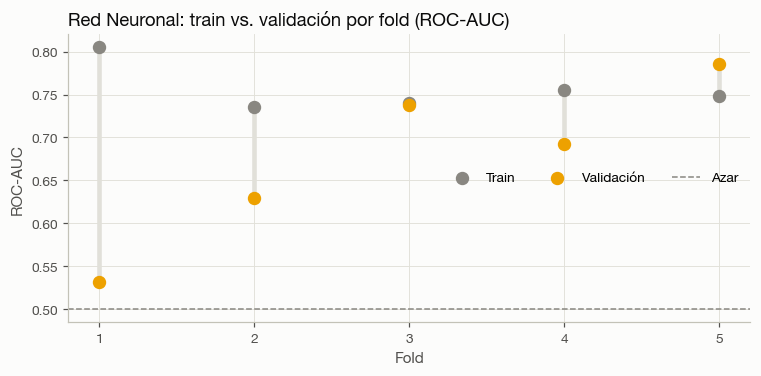

In [5]:
tabla_cv, oof, umbral = corridas[("cfg", i_mejor)]
display(tabla_cv.round(4))
display(E.resumen_cv(tabla_cv).round(4))
print(f"Umbral elegido (F1 máx. fuera de fold): {umbral:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.4))
for _, f in tabla_cv.iterrows():
    ax.plot([f["Fold"]] * 2, [f["ROC-AUC val"], f["ROC-AUC train"]], color=viz.GRID, linewidth=3, zorder=1)
ax.scatter(tabla_cv["Fold"], tabla_cv["ROC-AUC train"], color=viz.NEUTRO, s=60, label="Train", zorder=2)
ax.scatter(tabla_cv["Fold"], tabla_cv["ROC-AUC val"], color=COLOR, s=60, label="Validación", zorder=3)
ax.axhline(0.5, color=viz.NEUTRO, linestyle="--", linewidth=1, label="Azar")
ax.set_xticks(tabla_cv["Fold"]); ax.set_xlabel("Fold"); ax.set_ylabel("ROC-AUC")
ax.set_title(f"{NOMBRE}: train vs. validación por fold (ROC-AUC)"); ax.legend(ncol=3)
viz.guardar(fig, "cv_red_neuronal"); plt.show()

## Paso 4 · Entrenamiento final y curvas de aprendizaje
Se entrena con todo el train (con la cola más reciente para el early stopping). Las curvas se miden **igual** en
entrenamiento y validación: misma ponderación por clase y en modo inferencia (sin Dropout).

Si la curva de validación queda **por encima** de la de entrenamiento no es un error: la cola más reciente del train (feb–abr 2018)
es un periodo de oleadas, donde las variables de carga reciente son muy informativas y los retrasos son más fáciles de ordenar.
Lo que importa es que la validación deje de mejorar y el early stopping se quede con la mejor época.

Épocas entrenadas: 66 | mejor época: 58


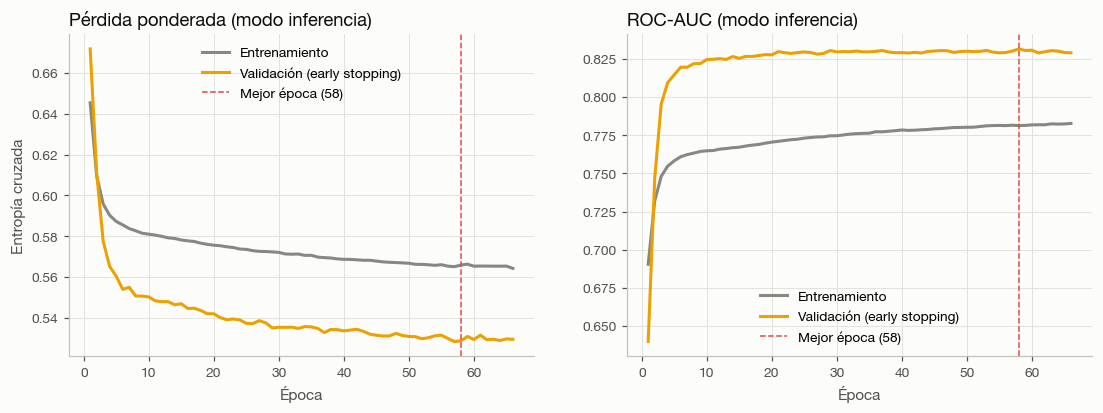

Model: "sequential_55"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_165 (Dense)               │ (None, 64)             │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_110 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_166 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_111 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_167 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_112 (Dropout)           │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_168 (Dense)               │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,789 (57.77 KB)

 Trainable params: 4,929 (19.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,860 (38.52 KB)

In [6]:
red_final = R.RedTabular(columnas, mejor_cfg, curvas=True).fit(X_train, y_train)
reg = red_final.cb_curvas.registro
epocas = np.arange(1, len(reg["loss_val"]) + 1)
print(f"Épocas entrenadas: {red_final.epocas_entrenadas} | mejor época: {red_final.mejor_epoca}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(epocas, reg["loss_train"], color=viz.NEUTRO, label="Entrenamiento")
axes[0].plot(epocas, reg["loss_val"], color=COLOR, label="Validación (early stopping)")
axes[0].set_title("Pérdida ponderada (modo inferencia)"); axes[0].set_ylabel("Entropía cruzada")
axes[1].plot(epocas, reg["auc_train"], color=viz.NEUTRO, label="Entrenamiento")
axes[1].plot(epocas, reg["auc_val"], color=COLOR, label="Validación (early stopping)")
axes[1].set_title("ROC-AUC (modo inferencia)")
for ax in axes:
    ax.axvline(red_final.mejor_epoca, color=viz.TARDIO, linestyle="--", linewidth=1, label=f"Mejor época ({red_final.mejor_epoca})")
    ax.set_xlabel("Época"); ax.legend()
viz.guardar(fig, "curvas_red_neuronal"); plt.show()
red_final.red.summary()

In [7]:
carpeta = M.guardar_artefactos(NOMBRE, columnas, {k: (list(v) if isinstance(v, tuple) else v) for k, v in mejor_cfg.items()},
                               tabla_cv, oof, umbral, None, extra={
    "conjunto_variables": mejor_set, "mejor_epoca": red_final.mejor_epoca, "n_variables_total": X_train.shape[1],
    "curvas": {k: [float(x) for x in v] for k, v in reg.items()}})
R.guardar_red(red_final, carpeta)
resultados_sets.to_csv(carpeta / "conjuntos_variables.csv", index=False)
busqueda.to_csv(carpeta / "busqueda.csv", index=False)
print("Artefactos guardados en", carpeta)

Artefactos guardados en /Users/fabiolajrz/Documents/proyecto_final_equipo_3/modelos/red_neuronal
